In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.datasets import make_blobs
from sklearn.metrics import silhouette_score

In [2]:
X, y_true = make_blobs(n_samples=500, centers=4, cluster_std=1.00, random_state=42)
df = pd.DataFrame(X, columns=['Feature_1', 'Feature_2'])

In [3]:
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
df["cluster_kmeans"] = kmeans.fit_predict(df[["Feature_1", "Feature_2"]])
kmeans_center = kmeans.cluster_centers_

dbscan = DBSCAN(eps=0.5, min_samples=5)
df["cluster_dbscan"] = dbscan.fit_predict(df[["Feature_1", "Feature_2"]])

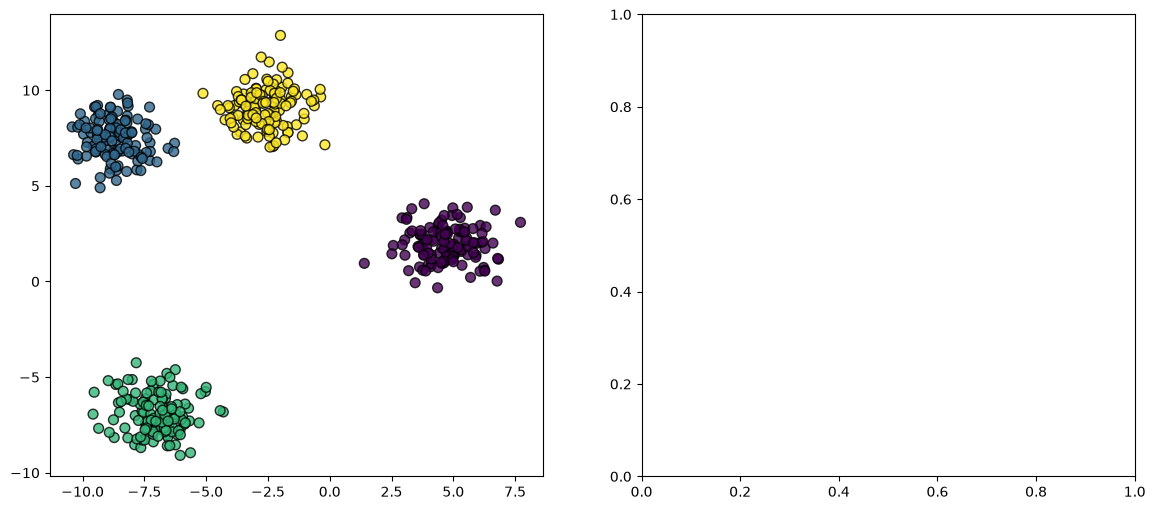

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

scatter1 = ax1.scatter(
    df["Feature_1"],
    df["Feature_2"],
    c=df['cluster_kmeans'],
    cmap = "viridis",
    marker = 'o',
    edgecolor = "k",
    s = 50,
    alpha = 0.8
)


In [5]:

ax1.scatter(
    kmeans_center[:, 0],
    kmeans_center[:, 1],
    c="red",
    marker="X",
    s=200,
    label = "Centers",
)
ax1.scatter(
    kmeans_center[:, 0],
    kmeans_center[:, 1],
    c="red",
    marker="X",
    s=200,
    label="Centers",
)
ax1.set_title("K-Means Clustering", fontsize=12, fontweight="bold")
ax1.set_xlabel("Feature 1")
ax1.set_ylabel("Feature 2")
ax1.legend()
ax1.grid(True, linestyle="--", alpha=0.6)
fig.colorbar(scatter1, ax=ax1, label="K-Means cluster")

scatter2 = ax2.scatter(
    df["Feature_1"],
    df["Feature_2"],
    c=df['cluster_dbscan'],
    cmap = "plasma",
    marker = 'o',
    edgecolor = "k",
    s = 50,
    alpha = 0.8
)
ax2.set_title("DBSCAN Clustering", fontsize=12, fontweight="bold")
ax2.set_xlabel("Feature 1")
ax2.set_ylabel("Feature 2")
ax2.grid(True, linestyle="--", alpha=0.6)
fig.colorbar(scatter2, ax=ax2, label="DBSCAN cluster (-1 = noise)")

plt.tight_layout()
plt.savefig("clustering_comparison.png", dpi=300)
plt.show()


<Figure size 640x480 with 0 Axes>

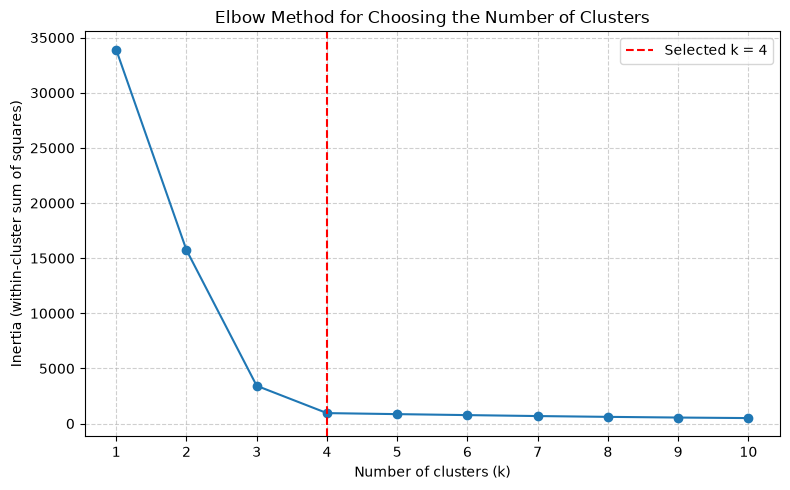

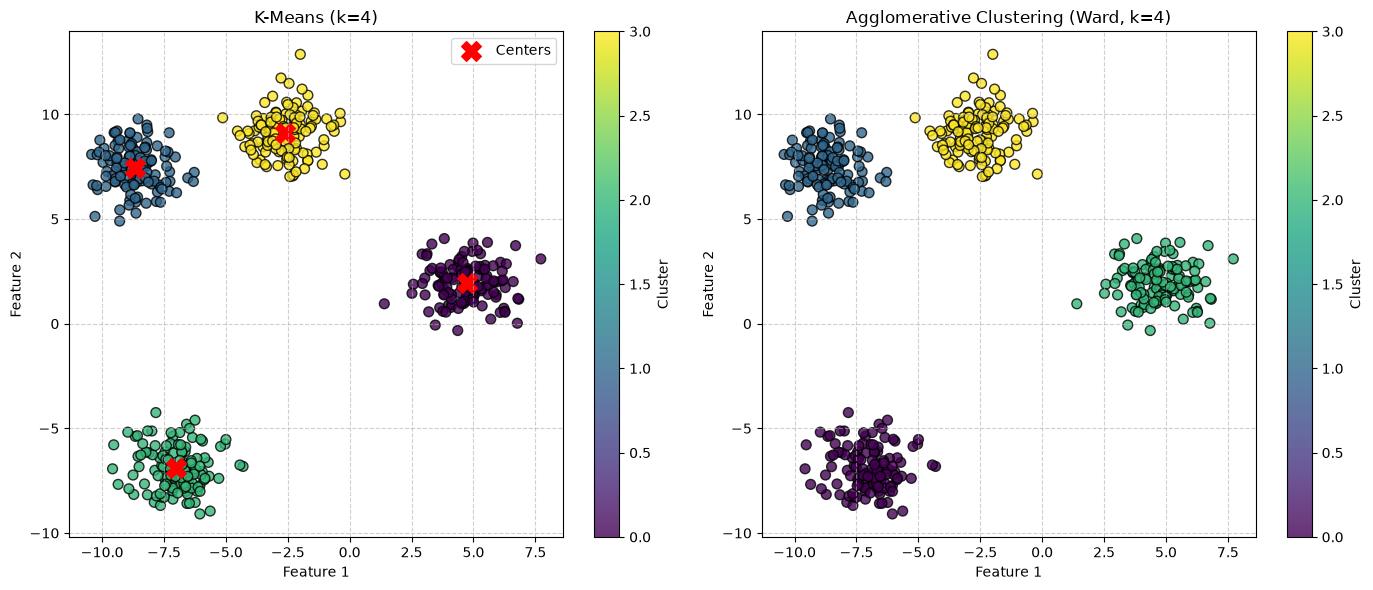

K-Means silhouette score: 0.791
Agglomerative silhouette score: 0.791


In [6]:
features = df[["Feature_1", "Feature_2"]]
k_values = range(1, 11)
inertias = []

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(features)
    inertias.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(list(k_values), inertias, marker="o")
plt.axvline(x=4, color="red", linestyle="--", label="Selected k = 4")
plt.title("Elbow Method for Choosing the Number of Clusters")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia (within-cluster sum of squares)")
plt.xticks(list(k_values))
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

selected_k = 4
kmeans_comparison = KMeans(n_clusters=selected_k, random_state=42, n_init=10)
kmeans_labels_comparison = kmeans_comparison.fit_predict(features)

agglomerative = AgglomerativeClustering(n_clusters=selected_k, linkage="ward")
agglomerative_labels = agglomerative.fit_predict(features)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
scatter1 = ax1.scatter(
    features["Feature_1"], features["Feature_2"],
    c=kmeans_labels_comparison, cmap="viridis", s=50,
    edgecolor="k", alpha=0.8,
)
ax1.scatter(
    kmeans_comparison.cluster_centers_[:, 0],
    kmeans_comparison.cluster_centers_[:, 1],
    c="red", marker="X", s=200, label="Centers",
)
ax1.set_title(f"K-Means (k={selected_k})")
ax1.set_xlabel("Feature 1")
ax1.set_ylabel("Feature 2")
ax1.legend()
ax1.grid(True, linestyle="--", alpha=0.6)
fig.colorbar(scatter1, ax=ax1, label="Cluster")

scatter2 = ax2.scatter(
    features["Feature_1"], features["Feature_2"],
    c=agglomerative_labels, cmap="viridis", s=50,
    edgecolor="k", alpha=0.8,
)
ax2.set_title(f"Agglomerative Clustering (Ward, k={selected_k})")
ax2.set_xlabel("Feature 1")
ax2.set_ylabel("Feature 2")
ax2.grid(True, linestyle="--", alpha=0.6)
fig.colorbar(scatter2, ax=ax2, label="Cluster")

plt.tight_layout()
plt.show()

print(f"K-Means silhouette score: {silhouette_score(features, kmeans_labels_comparison):.3f}")
print(f"Agglomerative silhouette score: {silhouette_score(features, agglomerative_labels):.3f}")